# Exercise 9: CNN


## CIFAR-10 classification using Keras Conv2D

The CIFAR-10 small photo classification problem is a standard dataset used in computer vision and deep learning.


## CIFAR-10 Photo Classification Dataset

CIFAR comes from the Canadian Institute For Advanced Research and the CIFAR-10 dataset was developed along with the CIFAR-100 dataset by researchers at the CIFAR institute. The dataset is comprised of 60,000 32×32 pixel color photographs of objects from 10 classes with following class labels:

0. airplane
1. automobile
2. bird
3. cat
4. deer
5. dog
6. frog
7. horse
8. ship
9. truck

![Alt text](https://student.labranet.jamk.fi/~rmika/images/ciraf-10.png)

It is relatively straightforward to achieve 80% classification accuracy. Top performance on the problem is achieved by deep learning convolutional neural networks with a classification accuracy above 90% on the test dataset.

__This exercises HAVE TO be done in CSC Puhti cloud environment.__

__NOTE: Try to get as good as possible accuracy. Accurary is one of the evalution criteria__.

TOP results will be found from [here](https://student.labranet.jamk.fi/~rmika/DLNN/TOP-scores.htm)



In [ ]:
import os, random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.utils import to_categorical

# Set random seed for reproducibility
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

# Class names for CIFAR-10 dataset
CLASS_NAMES = ["airplane", "automobile", "bird", "cat", "deer",
               "dog", "frog", "horse", "ship", "truck"]

I0000 00:00:1795435410.957546 2050815 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795435410.961235 2050815 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1795435412.073123 2050815 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795435415.092713 2050815 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_E

In [ ]:
# Load CIFAR-10 (from the local copy in ~/data if it exists, otherwise download it)
import pickle

# Load a single batch of CIFAR-10 data from the local directory
def load_batch(path):
    with open(path, "rb") as f:
        d = pickle.load(f, encoding="bytes")
    x = d[b"data"].reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1)
    y = np.array(d[b"labels"]).reshape(-1, 1)
    return x, y

# Load the CIFAR-10 dataset, either from local files or by downloading it
root = os.path.expanduser("~/data/cifar-10-batches-py")
if os.path.isdir(root):
    parts = [load_batch(f"{root}/data_batch_{i}") for i in range(1, 6)]
    x_train_full = np.concatenate([p[0] for p in parts])
    y_train_full = np.concatenate([p[1] for p in parts])
    x_test, y_test = load_batch(f"{root}/test_batch")
else:
    (x_train_full, y_train_full), (x_test, y_test) = cifar10.load_data()
print("Train:", x_train_full.shape, "Test:", x_test.shape)

# Normalise per channel (statistics from the training data only)
x_train_full = x_train_full.astype("float32")
x_test = x_test.astype("float32")
mean = x_train_full.mean(axis=(0, 1, 2))
std = x_train_full.std(axis=(0, 1, 2))
x_train_full = (x_train_full - mean) / std
x_test = (x_test - mean) / std

y_train_full_cat = to_categorical(y_train_full, 10)
y_test_cat = to_categorical(y_test, 10)

# Hold out 5,000 training images as validation set
rng = np.random.RandomState(SEED)
idx = rng.permutation(len(x_train_full))
val_idx, tr_idx = idx[:5000], idx[5000:]
x_val, y_val = x_train_full[val_idx], y_train_full_cat[val_idx]
x_train, y_train = x_train_full[tr_idx], y_train_full_cat[tr_idx]
print(x_train.shape, x_val.shape, x_test.shape)

BATCH_SIZE = 128
AUTOTUNE = tf.data.AUTOTUNE
train_ds = (tf.data.Dataset.from_tensor_slices((x_train, y_train))
            .shuffle(10000, seed=SEED).batch(BATCH_SIZE).prefetch(AUTOTUNE))
val_ds = tf.data.Dataset.from_tensor_slices((x_val, y_val)).batch(256).prefetch(AUTOTUNE)
test_ds = tf.data.Dataset.from_tensor_slices((x_test, y_test_cat)).batch(256).prefetch(AUTOTUNE)

Train: (50000, 32, 32, 3) Test: (10000, 32, 32, 3)
(45000, 32, 32, 3) (5000, 32, 32, 3) (10000, 32, 32, 3)


E0000 00:00:1795435417.513930 2050815 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [ ]:
# VGG-style CNN: 3 blocks of 2 conv layers (64/128/256 filters) with batch norm and dropout
WEIGHT_DECAY = 5e-4

def conv_bn_relu(x, filters):
    x = layers.Conv2D(filters, 3, padding="same", use_bias=False,
                      kernel_initializer="he_normal",
                      kernel_regularizer=regularizers.l2(WEIGHT_DECAY))(x)
    x = layers.BatchNormalization()(x)
    return layers.Activation("relu")(x)

def conv_block(x, filters, dropout):
    x = conv_bn_relu(x, filters)
    x = conv_bn_relu(x, filters)
    x = layers.MaxPooling2D(2)(x)
    return layers.Dropout(dropout)(x)

def build_model():
    inputs = keras.Input(shape=(32, 32, 3))
    # Data augmentation (only active during training)
    x = layers.RandomFlip("horizontal")(inputs)
    x = layers.RandomTranslation(0.1, 0.1, fill_mode="reflect")(x)
    x = layers.RandomZoom(0.1, fill_mode="reflect")(x)

    x = conv_block(x, 64, 0.2)
    x = conv_block(x, 128, 0.3)
    x = conv_block(x, 256, 0.4)

    x = layers.Flatten()(x)
    x = layers.Dense(256, use_bias=False, kernel_initializer="he_normal",
                     kernel_regularizer=regularizers.l2(WEIGHT_DECAY))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(10, activation="softmax")(x)
    return keras.Model(inputs, outputs, name="cifar10_vgg_bn_small")

model = build_model()
model.summary()

Model: "cifar10_vgg_bn_small"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation              │ (None, 32, 32, 3)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 64)     │         1,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 256)      │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 256)      │         1,024 │
│ (BatchNormalization)            │                        │             

 Total params: 2,200,266 (8.39 MB)

 Trainable params: 2,197,962 (8.38 MB)

 Non-trainable params: 2,304 (9.00 KB)

In [ ]:
# Train: SGD + Nesterov momentum, cosine learning-rate decay, label smoothing.

EPOCHS = 100
steps_per_epoch = int(np.ceil(len(x_train) / BATCH_SIZE))

lr_schedule = keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=0.05,
    decay_steps=EPOCHS * steps_per_epoch,
    alpha=1e-3)

model.compile(
    optimizer=keras.optimizers.SGD(learning_rate=lr_schedule, momentum=0.9, nesterov=True),
    loss=keras.losses.CategoricalCrossentropy(label_smoothing=0.1),
    metrics=["accuracy"])

ckpt = keras.callbacks.ModelCheckpoint(
    "best_cifar10.weights.h5", monitor="val_accuracy", mode="max",
    save_best_only=True, save_weights_only=True)

history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS,
                    callbacks=[ckpt], verbose=2)

Epoch 1/100


/users/bishtdin/.local/x86_64/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


352/352 - 49s - 139ms/step - accuracy: 0.3966 - loss: 2.8946 - val_accuracy: 0.2980 - val_loss: 3.1483
Epoch 2/100
352/352 - 47s - 134ms/step - accuracy: 0.5530 - loss: 2.3181 - val_accuracy: 0.5258 - val_loss: 2.4077
Epoch 3/100
352/352 - 47s - 134ms/step - accuracy: 0.6302 - loss: 1.9831 - val_accuracy: 0.6070 - val_loss: 1.9473
Epoch 4/100
352/352 - 47s - 133ms/step - accuracy: 0.6774 - loss: 1.7642 - val_accuracy: 0.6854 - val_loss: 1.6799
Epoch 5/100
352/352 - 47s - 133ms/step - accuracy: 0.7032 - loss: 1.6222 - val_accuracy: 0.7326 - val_loss: 1.5189
Epoch 6/100
352/352 - 47s - 133ms/step - accuracy: 0.7252 - loss: 1.5205 - val_accuracy: 0.7244 - val_loss: 1.5012
Epoch 7/100
352/352 - 47s - 133ms/step - accuracy: 0.7399 - loss: 1.4463 - val_accuracy: 0.7200 - val_loss: 1.4612
Epoch 8/100
352/352 - 47s - 134ms/step - accuracy: 0.7530 - loss: 1.3913 - val_accuracy: 0.7736 - val_loss: 1.3267
Epoch 9/100
352/352 - 47s - 133ms/step - accuracy: 0.7643 - loss: 1.3509 - val_accuracy: 0.7

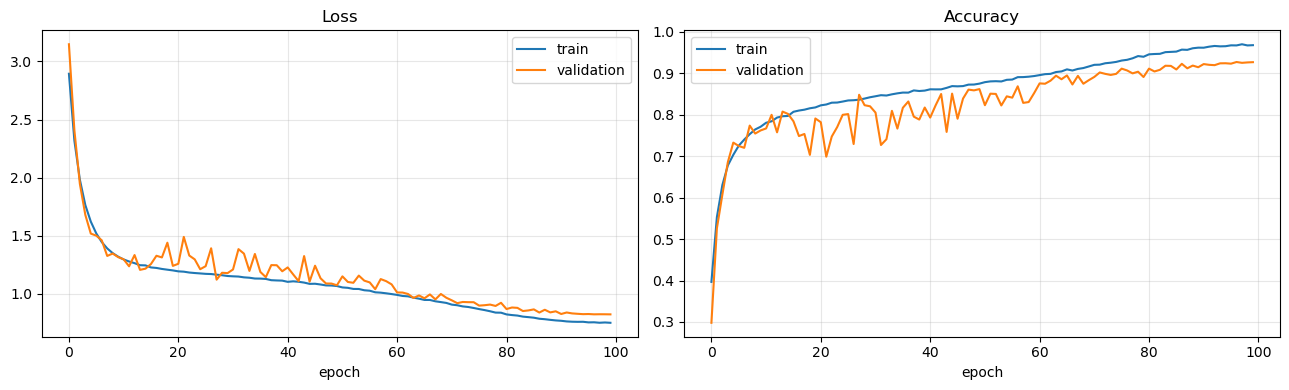

Best epoch: 97, val acc: 0.9270


In [5]:
# Learning curves
h = history.history
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(h["loss"], label="train"); ax[0].plot(h["val_loss"], label="validation")
ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(h["accuracy"], label="train"); ax[1].plot(h["val_accuracy"], label="validation")
ax[1].set_title("Accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

best_ep = int(np.argmax(h["val_accuracy"]))
print(f"Best epoch: {best_ep + 1}, val acc: {h['val_accuracy'][best_ep]:.4f}")

In [6]:
# Evaluate the best model on the test set
model.load_weights("best_cifar10.weights.h5")
y_true = y_test.ravel()
y_pred = model.predict(x_test, batch_size=256, verbose=0).argmax(1)
print(f"Test accuracy: {np.mean(y_pred == y_true) * 100:.2f} %")

# Per-class accuracy and the most common confusions
cm = np.zeros((10, 10), dtype=int)
np.add.at(cm, (y_true, y_pred), 1)
print("\nPer-class accuracy:")
for name, a in sorted(zip(CLASS_NAMES, cm.diagonal() / cm.sum(1)), key=lambda t: t[1]):
    print(f"  {name:12s} {a:.3f}")

off = cm.copy(); np.fill_diagonal(off, 0)
print("\nMost common confusions (true -> predicted):")
for k in np.argsort(off.ravel())[::-1][:5]:
    t, q = divmod(k, 10)
    print(f"  {CLASS_NAMES[t]} -> {CLASS_NAMES[q]}: {off[t, q]}")

Test accuracy: 92.02 %

Per-class accuracy:
  cat          0.798
  dog          0.871
  bird         0.877
  airplane     0.917
  deer         0.921
  ship         0.949
  horse        0.950
  truck        0.962
  frog         0.976
  automobile   0.981

Most common confusions (true -> predicted):
  cat -> dog: 80
  dog -> cat: 61
  cat -> frog: 53
  bird -> frog: 38
  deer -> frog: 28


# Conclusion

## Results
The final CNN reached **92.02 %** test accuracy. The best validation accuracy was 92.70 % at epoch 97. Training took 100 epochs with 8 CPU cores of ROIHU (no GPU).

Training accuracy ended at 96.8 % and validation accuracy at 92.7 %. The gap of about 4 points shows mild overfitting, which is small given the 2.2 M parameters and is kept in check by dropout, weight decay and augmentation. The validation curve was noisy in the middle of training and became smooth as the learning rate decayed.

The weakest classes were cat (79.8 %), dog (87.1 %) and bird (87.7 %). The most common confusions were cat -> dog (80 images), dog -> cat (61), cat -> frog (53) and bird -> frog (38), which is expected for similar animal classes at only 32x32 pixels. The strongest classes were automobile (98.1 %), frog (97.6 %) and truck (96.2 %).

## Development process
I started with a small VGG-style CNN (three blocks of two 3x3 convolutions with 32/64/128 filters, 0.55 M parameters), which could be trained on CPU in about 25 minutes. It reached 89.71 % test accuracy. Training and validation accuracy were almost equal (91.0 % and 90.6 %) and both were still creeping up when the learning rate reached zero, so the model was limited by its size rather than by overfitting.

I therefore doubled the width of the network (64/128/256 filters and a 256-unit dense layer, 2.2 M parameters) and added random zoom to the augmentation. Everything else was kept the same so that the improvement could be attributed to the model: batch normalization after every convolution, progressive dropout (0.2 / 0.3 / 0.4, and 0.5 in the dense layer), L2 weight decay, random flip and shift augmentation, label smoothing (0.1), and SGD with Nesterov momentum and cosine learning-rate decay over 100 epochs. This raised the test accuracy by 2.3 points to 92.02 %, at the cost of about three times longer training (80 instead of 25 minutes).

The best epoch was selected using a separate validation set of 5,000 training images, and the test set was used only once at the end.

## AI Usage
I used AI as an assistant in this exercise. It helped me check my code against the exercise, remove unused code and understand the results and document the conclusion in an organised way.
